# 03 · Manutenção preditiva: falha da luminária nos próximos 14 dias

Notebook do **modelo principal da proposta** (Ideação, Proposição e Planejamento, funcionalidade 2 e seções
g.2, g.3, g.5 e g.7). Pergunta do gestor: *quais luminárias devem ser inspecionadas nas próximas duas semanas?*

- **Dados:** parque de 500 luminárias **simuladas** com degradação (`applications/simulador/parque.py`), calibrado
  com os chamados reais de lâmpada apagada da Emlurb. Premissas em `docs/PREMISSAS_SIMULADOR.md`.
- **Rótulo:** y(t) = 1 se a luminária falhar em (t, t + 14 dias].
- **Protocolo:** divisão temporal 70/15/15 com intervalo de 14 dias, Optuna walk-forward no treino, PR-AUC como
  métrica principal, baselines (regra simples e aleatório estratificado), probabilidade calibrada, robustez.
- O treino em si está em `applications/ml/src/treinar_falha.py` (e no MLflow, experimento `falha_14d`); este
  notebook explora os dados e lê os resultados para o relatório.

> Todos os números abaixo são **desempenho sobre dados simulados** (proposta, g.5).

In [1]:
import json, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "ml").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent                      # sobe até applications/
for p in (RAIZ, RAIZ / "ml" / "src", RAIZ / "simulador"):
    sys.path.insert(0, str(p))
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.calibration import calibration_curve
from parque_features import FEATURES, construir_features, limpar_telemetria, linhas_para_modelo, rotular
import treinar_falha as T
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
catalogo, telemetria, origem = T.carregar_dados()
print(f"origem dos dados: {origem} | {len(catalogo)} luminárias | {len(telemetria):,} leituras diárias")

origem dos dados: banco | 500 luminárias | 503,936 leituras diárias


## 1. O parque simulado e a coerência com a Emlurb (seção g.7)

taxa mensal simulada 0.0246 x Emlurb 0.0239
correlação da sazonalidade: 0.744 (parque de calibração), 0.531 (histórico de 500 luminárias)


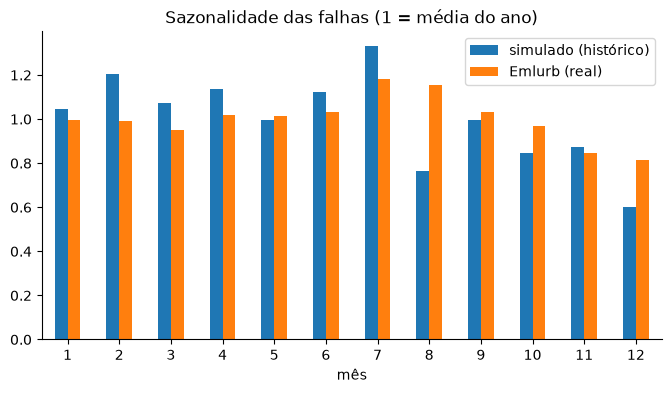

In [2]:
calib = json.loads((RAIZ / "ml" / "data" / "simulado" / "calibracao.json").read_text(encoding="utf-8"))
print(f"taxa mensal simulada {calib['taxa_mensal_simulada']:.4f} x Emlurb {calib['taxa_mensal_emlurb']:.4f}")
print(f"correlação da sazonalidade: {calib['correlacao_sazonalidade_calibracao']} (parque de calibração), "
      f"{calib['correlacao_sazonalidade']} (histórico de 500 luminárias)")
saz = pd.DataFrame({"simulado (histórico)": pd.Series(calib["sazonalidade_simulada"]),
                    "Emlurb (real)": pd.Series(calib["sazonalidade_emlurb"])})
saz.index = saz.index.astype(int); saz = saz.sort_index()
saz.plot(kind="bar", rot=0, title="Sazonalidade das falhas (1 = média do ano)"); plt.xlabel("mês"); plt.show()

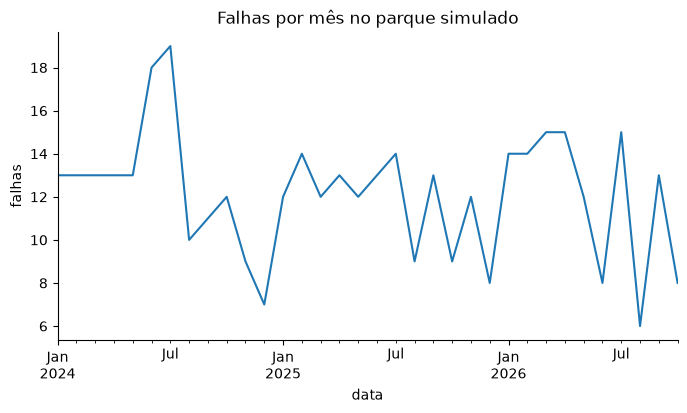

estado
OK            0.8820
CINTILANDO    0.1131
APAGADA       0.0049
Name: proportion, dtype: float64
potência: {100.0: 201, 60.0: 193, 150.0: 106} | classes de via: {'P4': 148, 'P3': 130, 'P5': 98, 'P6': 53, 'P2': 44, 'P1': 27}


In [3]:
t = telemetria.assign(data=pd.to_datetime(telemetria["data"]))
falhas_mes = t[t["falha"] == 1].groupby(t["data"].dt.to_period("M")).size()
falhas_mes.plot(title="Falhas por mês no parque simulado"); plt.ylabel("falhas"); plt.show()
print(t["estado"].value_counts(normalize=True).round(4))
print("potência:", catalogo["potencia_w"].value_counts().to_dict(), "| classes de via:", catalogo["classe_via"].value_counts().to_dict())

## 2. Limpeza (o que a etapa `validar_dados` do Airflow faz)

O simulador gera falhas de medição de propósito: 0,5% das leituras não chegam e 0,2% chegam impossíveis
(temperatura −40 °C, tensão 0 V, corrente negativa). A limpeza remove duplicatas, troca o impossível por
ausente e preenche lacunas de até 2 leituras com a última leitura válida da mesma luminária.

{'lidas': 503936, 'duplicadas': 0, 'linhas_com_ausente': 1002, 'preenchidas': 1002, 'descartadas': 0, 'validas': 503936}


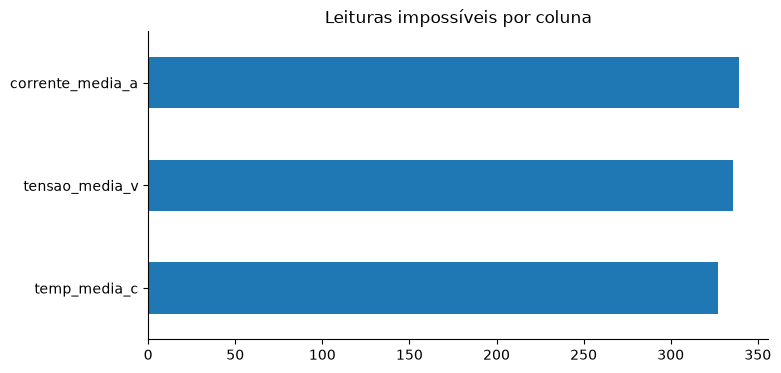

In [4]:
limpo, relatorio = limpar_telemetria(telemetria)
print({k: v for k, v in relatorio.items() if k != "leituras_invalidas"})
pd.Series(relatorio["leituras_invalidas"]).loc[lambda s: s > 0].plot(kind="barh", title="Leituras impossíveis por coluna"); plt.show()

## 3. Atributos e rótulo: o que muda antes de uma falha

In [5]:
df = rotular(construir_features(limpo, catalogo))
df = df[linhas_para_modelo(df)]
print(f"{len(df):,} linhas para o modelo; {df['y'].sum():,} positivas ({df['y'].mean():.2%}): classes muito desbalanceadas")
resumo = df.groupby("y")[["ripple_7d", "dias_cintilando_30d", "carga_rel_7d", "temp_7d", "surtos_90d", "horas_acumuladas"]].mean().T
resumo.columns = ["não falha em 14 dias", "falha em 14 dias"]
resumo.round(3)

501,449 linhas para o modelo; 5,670 positivas (1.13%): classes muito desbalanceadas


,não falha em 14 dias,falha em 14 dias
ripple_7d,10.440,22.927
dias_cintilando_30d,3.177,12.015
carga_rel_7d,1.016,1.027
temp_7d,52.315,54.170
surtos_90d,0.782,0.844
horas_acumuladas,10037.838,15927.890


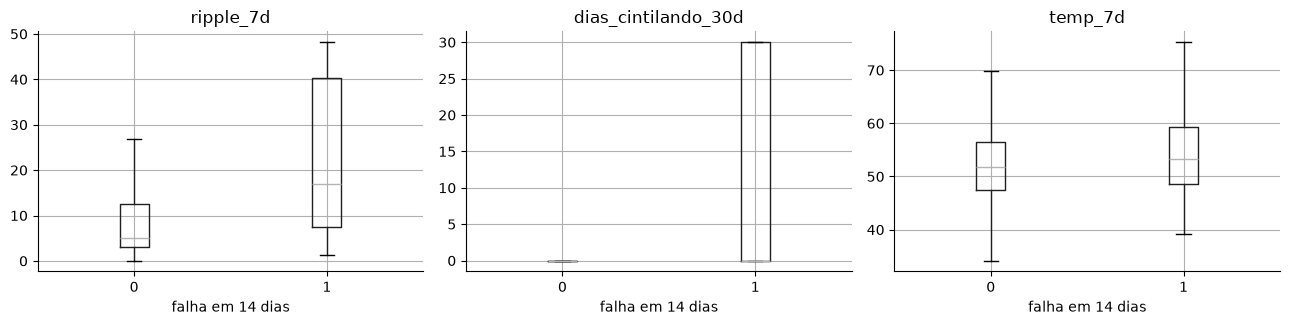

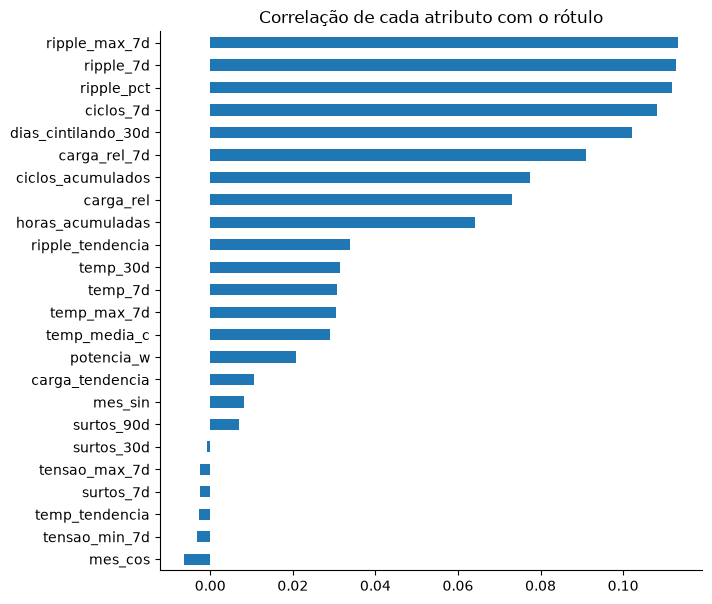

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(eixos, ["ripple_7d", "dias_cintilando_30d", "temp_7d"]):
    df.boxplot(column=col, by="y", ax=ax, showfliers=False); ax.set_title(col); ax.set_xlabel("falha em 14 dias")
plt.suptitle(""); plt.tight_layout(); plt.show()
corr = df[FEATURES + ["y"]].corr()["y"].drop("y").sort_values()
corr.plot(kind="barh", figsize=(7, 7), title="Correlação de cada atributo com o rótulo"); plt.show()

## 4. Divisão temporal e comparação dos modelos

Treino (~70% dos dias), validação (~15%) e teste (~15%), com 14 dias de intervalo entre eles, porque o rótulo
olha 14 dias à frente. Os modelos são escolhidos pela **PR-AUC na validação**; o teste é medido uma vez só.

In [7]:
meta = json.loads((RAIZ / "ml" / "models" / "metadados_falha.json").read_text(encoding="utf-8"))
print(f"modelo em produção: {meta['modelo']} ({meta['calibracao']}), treinado em {meta['treinado_em']}")
print(pd.DataFrame(meta["periodos"], index=["início", "fim", "linhas", "positivas"]).T)
tabela = pd.DataFrame(meta["metricas"]).T
cols = ["val_pr_auc", "teste_pr_auc", "teste_roc_auc", "teste_precision_at_k", "teste_recall_at_k", "teste_brier", "teste_f1"]
tabela[[c for c in cols if c in tabela]].sort_values("val_pr_auc", ascending=False).round(4)

modelo em produção: xgboost (isotonic), treinado em 2026-11-26T21:31:49
               início         fim  linhas positivas
treino     2024-01-31  2025-10-28  315404      3566
validacao  2025-11-11  2026-03-16   62359       776
teste      2026-03-30  2026-08-17   69798       712


,val_pr_auc,teste_pr_auc,teste_roc_auc,teste_precision_at_k,teste_recall_at_k,teste_brier,teste_f1
xgboost_calibrado,0.0623,0.0709,0.7741,0.1177,0.2265,0.0097,0.1467
xgboost,0.0572,0.0799,0.7968,0.1142,0.2328,0.2043,NaN
random_forest,0.0472,0.0764,0.8009,0.0908,0.1679,0.1895,NaN
regra_temperatura_7d,0.0318,0.0196,0.5868,0.0426,0.1115,0.2347,NaN
regra_horas_acumuladas,0.0195,0.0381,0.6744,0.0206,0.0327,0.0493,NaN
aleatorio_estratificado,0.0126,0.0102,0.5007,0.0121,0.0230,0.0213,NaN


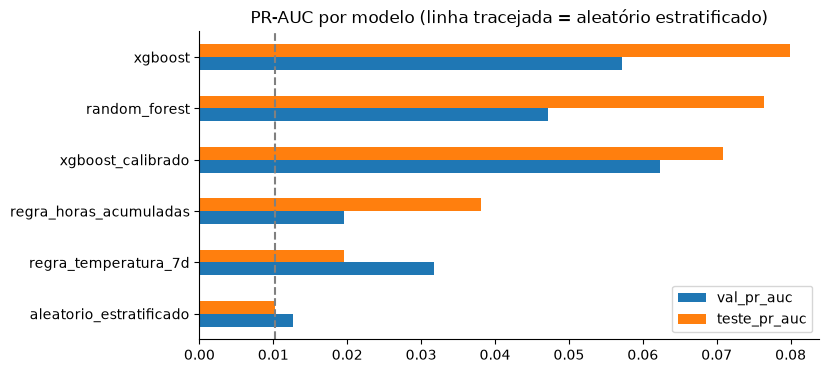

vence os baselines: True | melhor baseline: regra_temperatura_7d


In [8]:
ax = tabela[["val_pr_auc", "teste_pr_auc"]].sort_values("teste_pr_auc").plot(kind="barh", figsize=(8, 4))
ax.axvline(tabela.loc["aleatorio_estratificado", "teste_pr_auc"], ls="--", color="gray")
ax.set_title("PR-AUC por modelo (linha tracejada = aleatório estratificado)"); plt.show()
print("vence os baselines:", meta["vence_baselines"], "| melhor baseline:", meta["melhor_baseline"])

## 5. Curvas no teste: precisão x recall e calibração

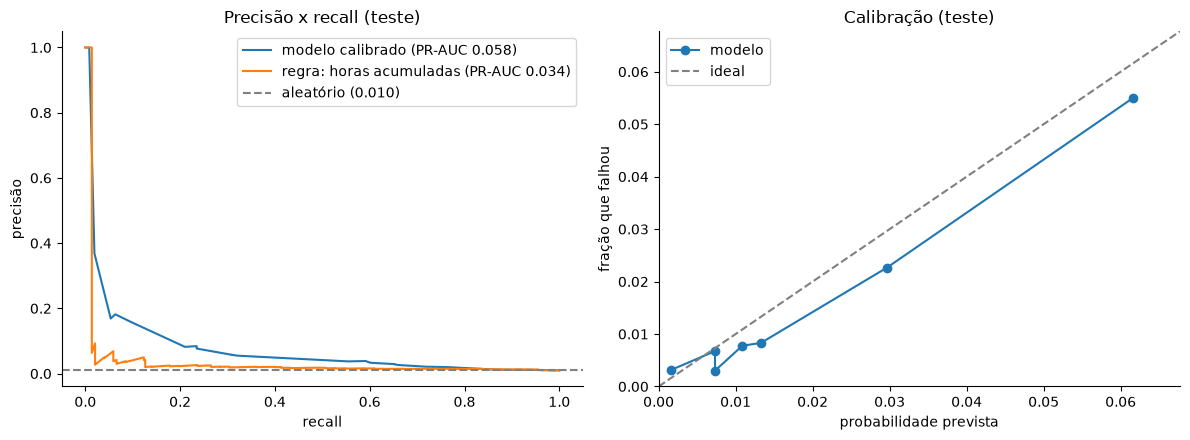

precision@10 = 0.098 | recall@10 = 0.183 (média por dia do teste)


In [9]:
partes = T.dividir(df)
teste, treino = partes["teste"], partes["treino"]
modelo = joblib.load(RAIZ / "ml" / "models" / "modelo_falha.joblib")
p_modelo = modelo.predict_proba(teste[FEATURES])[:, 1]
regra = T.RegraSimples("horas_acumuladas").fit(treino[FEATURES])
p_regra = regra.predict_proba(teste[FEATURES])[:, 1]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
for nome, p in [("modelo calibrado", p_modelo), ("regra: horas acumuladas", p_regra)]:
    pr, rc, _ = precision_recall_curve(teste["y"], p)
    a.plot(rc, pr, label=f"{nome} (PR-AUC {average_precision_score(teste['y'], p):.3f})")
a.axhline(teste["y"].mean(), ls="--", color="gray", label=f"aleatório ({teste['y'].mean():.3f})")
a.set_xlabel("recall"); a.set_ylabel("precisão"); a.legend(); a.set_title("Precisão x recall (teste)")
frac, media = calibration_curve(teste["y"], p_modelo, n_bins=10, strategy="quantile")
b.plot(media, frac, "o-", label="modelo"); lim = max(media.max(), frac.max()) * 1.1
b.plot([0, lim], [0, lim], "--", color="gray", label="ideal"); b.set_xlim(0, lim); b.set_ylim(0, lim)
b.set_xlabel("probabilidade prevista"); b.set_ylabel("fração que falhou"); b.legend(); b.set_title("Calibração (teste)")
plt.tight_layout(); plt.show()
p_k, r_k = T.em_k(teste, p_modelo)
print(f"precision@{T.CAPACIDADE_K} = {p_k:.3f} | recall@{T.CAPACIDADE_K} = {r_k:.3f} (média por dia do teste)")

## 6. O que o modelo usa e se ele aguenta premissas diferentes (robustez, g.5)

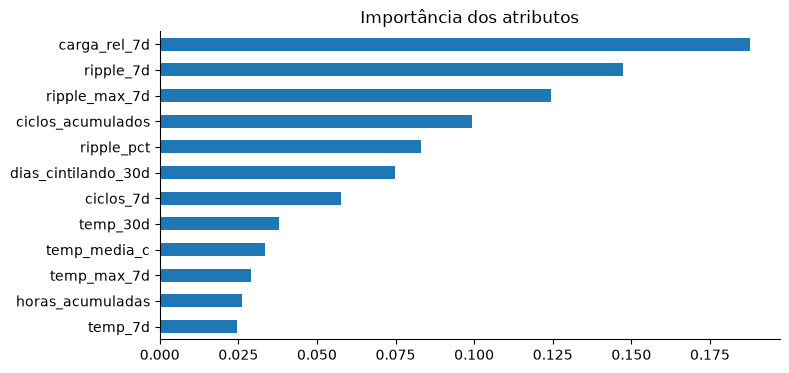

,pr_auc,roc_auc,brier,taxa_positivos
noites_mais_quentes_+3C,0.0420,0.7445,0.0119,0.0122
surtos_em_dobro,0.0578,0.7837,0.0153,0.0157
lote_mais_irregular,0.0342,0.7230,0.0115,0.0114
teste (cenário base),0.0709,0.7741,0.0097,0.0102


In [10]:
pd.Series(meta["importancia_features"]).sort_values().tail(12).plot(kind="barh", title="Importância dos atributos"); plt.show()
rob = pd.DataFrame(meta["robustez"]).T
rob.loc["teste (cenário base)"] = {"pr_auc": tabela.loc[f"{meta['modelo']}_calibrado", "teste_pr_auc"],
                                    "roc_auc": tabela.loc[f"{meta['modelo']}_calibrado", "teste_roc_auc"],
                                    "brier": tabela.loc[f"{meta['modelo']}_calibrado", "teste_brier"],
                                    "taxa_positivos": tabela.loc[f"{meta['modelo']}_calibrado", "teste_taxa_positivos"]}
rob[["pr_auc", "roc_auc", "brier", "taxa_positivos"]].astype(float).round(4)

## 7. Leitura crítica (para discutir no relatório)

- **Dados simulados.** O modelo aprende mecanismos que o grupo escreveu no simulador. Para reduzir o risco de
  ele só "decorar as regras", a falha é sorteada (não é função dos atributos), depende de fatores latentes que o
  modelo não vê e tem 15% de falhas externas imprevisíveis. Mesmo assim, o resultado vale para o mundo simulado.
- **Desbalanceamento.** Cerca de 1% das linhas são positivas; por isso a métrica principal é PR-AUC, e a
  referência de "chute" é a taxa de positivos (linha tracejada), não 0,5.
- **Operação.** precision@k e recall@k traduzem o modelo para a equipe: das k luminárias que ela consegue
  inspecionar por quinzena, quantas iam mesmo falhar.
- **Calibração.** A probabilidade calibrada é o que entra no painel e no score de prioridade com o CPTED.
- **Robustez.** Se a PR-AUC cai muito nos cenários alterados, o modelo depende demais das premissas exatas
  do simulador; isso deve ser reportado como limitação.
- **Trabalho futuro.** Validar com telemetria real (a Emlurb só serviu para calibrar taxa e sazonalidade).